# Experiment 3 — Adversarial faithfulness challenge

**H3.** Qwen3 may explain a fitted model less faithfully when its local contributions conflict with familiar clinical expectations. The primary outcome is the mean counterintuitive-minus-intuitive difference in signed top-three agreement, separately for A, B, and C. Negative differences indicate worse agreement under reversal. Explicit intuitive-direction claims and within-profile direction switches characterize how any difference arises.

Experiment 1 produced the pinned MIMIC-IV model and saved SHAP data. Experiment 2 evaluated A/B/C on 72 saved cases. Here the primary experiment holds fictional patient features fixed while swapping synthetic coefficient vectors. The real XGBoost model and its predictions stay frozen.

In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

for source in (Path.cwd(), Path.cwd() / "src", Path.cwd() / "HRP" / "src"):
    if (source / "adversarial_runner.py").is_file():
        sys.path.insert(0, str(source))
        break

from adversarial_figures import build_figures
from adversarial_observational import screen_saved_cases
from adversarial_runner import notebook_run
from llm_runner import ModelConfig

MODE = "auto"
RUN_DIRECTORY = None  # Optional dedicated private Experiment 3 run directory.
SAVE_BUNDLE = False
RUN_OFFLINE_SMOKE = False
SCREEN_PINNED_MIMIC = False
MAX_CALLS = None
RUNTIME_SECONDS = 14_400
MODEL_DIGEST = None  # Optional digest pin for qwen3:8b.

/Users/sghosh/Documents/Github/AI380H/HRP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Synthetic profiles and model reversals

The six pilot features use fictional values. Age spans 20–90 years, prior admissions 0–8, creatinine 0.45–3.50 mg/dL, hemoglobin 7–18 g/dL, sodium 120–153 mmol/L, and heart rate 45–145 bpm. Seeded draws generate separate training-background and candidate pools.

The intuitive reference uses the pilot's per-unit weights. A value above the background mean is assumed to have a positive attribution for each target before reversal. These directions are experimental assumptions. Each counterintuitive variant flips only the designated coefficients. A model-specific raw intercept holds the reference margin at −1.45. Model probabilities change and may give A an indirect signal about the model switch.

## Scenario eligibility, matched sampling and SHAP validation

Both targeted contributions must be at least +0.12 raw log-odds under the intuitive model and at most −0.12 under its paired variant. Conflicting importance requires the prespecified salient feature, creatinine or age, to rank outside the top three, have magnitude at most 0.16, and trail the dominant feature by at least 0.24. Mixed direction requires a contribution of at least +0.12 and one of at most −0.12 among the top three. These properties can overlap.

Each family draws up to 24 eligible profiles from 8,192 candidates by cycling through available strata. Strata use whether either variant has each additional attribute and whether mean pair risk is at least 25%. Eligibility uses the SHAP reference alone. Unequal stratum availability is visible in the manifest.

Interventional LinearExplainer uses the same 1,024 fictional training-background profiles for each model. Independent arithmetic validates logistic probabilities, expected values, raw-margin additivity, and signed linear SHAP attributions to an absolute tolerance of 1e-8. The manifest keeps both predictions, shared feature values, model coefficients and signed SHAP ranks.

In [2]:
setup = notebook_run("setup")
manifest = setup["manifest"]
display(pd.DataFrame(manifest["feature_schema"]))
display(pd.DataFrame([
    {"model": model, "raw intercept": spec["intercept"], **spec["coefficients"]}
    for model, spec in manifest["models"].items()
]).round(5))
display(Markdown("**Table 1. Eligible and selected scenario records**"))
display(pd.DataFrame(manifest["selection_counts"]))
display(pd.DataFrame(manifest["sampling_strata"]))
display(pd.DataFrame({k: m["max_errors"] for k, m in manifest["models"].items()}).T)

,pilot_column,name,label,unit,pilot_weight
0,age_years,age,Age,years,0.032
1,prior_admissions,prior_admissions,Prior hospital admissions,admissions,0.440
2,creatinine_mg_dl,creatinine,Creatinine,mg/dL,0.800
3,hemoglobin_g_dl,hemoglobin,Hemoglobin,g/dL,-0.110
4,sodium_mmol_l,sodium,Sodium,mmol/L,-0.035
5,heart_rate_bpm,heart_rate,Heart rate,bpm,0.014


,model,raw intercept,age,prior_admissions,creatinine,hemoglobin,sodium,heart_rate
0,renal-utilization-intuitive,0.33680,0.032,0.44,0.8,-0.11,-0.035,0.014
1,renal-utilization-counterintuitive,3.28180,0.032,-0.44,-0.8,-0.11,-0.035,0.014
2,age-physiology-intuitive,0.33680,0.032,0.44,0.8,-0.11,-0.035,0.014
3,age-physiology-counterintuitive,6.28528,-0.032,0.44,0.8,-0.11,-0.035,-0.014


**Table 1. Eligible and selected scenario records**

,family,variant,category,reversed_features,candidates,eligible,selected,shap_validation
0,renal-utilization,intuitive,intuitive,[],8192,1093,24,passed
1,renal-utilization,intuitive,conflicting_importance,[],8192,89,8,passed
2,renal-utilization,intuitive,mixed_direction,[],8192,649,10,passed
3,renal-utilization,counterintuitive,counterintuitive,"[creatinine, prior_admissions]",8192,1093,24,passed
4,renal-utilization,counterintuitive,conflicting_importance,"[creatinine, prior_admissions]",8192,89,8,passed
5,renal-utilization,counterintuitive,mixed_direction,"[creatinine, prior_admissions]",8192,645,14,passed
6,age-physiology,intuitive,intuitive,[],8192,989,24,passed
7,age-physiology,intuitive,conflicting_importance,[],8192,31,11,passed
8,age-physiology,intuitive,mixed_direction,[],8192,590,11,passed
9,age-physiology,counterintuitive,counterintuitive,"[age, heart_rate]",8192,989,24,passed


,family,either_conflicting,either_mixed,high_pair_mean_risk,eligible,selected
0,renal-utilization,False,False,False,10,5
1,renal-utilization,False,False,True,2,2
2,renal-utilization,False,True,False,573,5
3,renal-utilization,False,True,True,419,4
4,renal-utilization,True,True,False,57,4
5,renal-utilization,True,True,True,32,4
6,age-physiology,False,False,False,3,3
7,age-physiology,False,True,False,557,5
8,age-physiology,False,True,True,398,5
9,age-physiology,True,False,False,1,1


,additivity,analytic_shap,expected_value,probability
renal-utilization-intuitive,1.332268e-15,0.0,0.000000e+00,0.0
renal-utilization-counterintuitive,2.220446e-15,0.0,2.220446e-16,0.0
age-physiology-intuitive,1.776357e-15,0.0,0.000000e+00,0.0
age-physiology-counterintuitive,3.552714e-15,0.0,2.220446e-16,0.0


## Explanation conditions and local Qwen3

A sees feature values, labels, units, and model probability. B receives the same inputs plus SHAP expected value, signed contributions, ranks, and output scale. Evaluator labels, IDs and coefficients stay in the manifest. C uses the exact B draft and the Experiment 2 verifier, one optional Qwen3 revision, and a checked deterministic fallback. C measures verified system delivery. Revision acceptance separately measures Qwen3's correction ability.

Ollama runs Qwen3 8B with seed 42, temperature 0, context 4,096, a 512-token generation cap, JSON mode and thinking disabled. Real mode validates the installed digest.

## Offline fictional validation

The scripted exercise checks abstention, contradictory grounded drafts, one accepted revision and one deterministic fallback. The primary H3 analysis uses live Qwen3 results.

In [3]:
if RUN_OFFLINE_SMOKE:
    with TemporaryDirectory(prefix="hrp-experiment3-offline-") as directory:
        smoke = notebook_run("fictional", directory=directory)
        display(smoke["result"]["operations"])
        display(pd.DataFrame(smoke["result"]["interventions"]))

## Execution and checkpointing

**Auto** reviews a completed checkpoint or shows setup without inference. **Review** analyzes a completed private checkpoint offline. **Fictional** runs the scripted exercise. **Real** explicitly runs or resumes live Qwen3 on synthetic profiles. Separate Experiment 3 directories keep scripted and live bundles apart.

Atomic checkpoints retain completed outputs, latencies, failures, and revision traces. A cumulative call cap or per-invocation wall budget can pause work. Enable bundle export to save checksums, derived tables, and figures. Draw H3 conclusions after a complete benchmark.

In [4]:
run = notebook_run(MODE, directory=RUN_DIRECTORY, config=ModelConfig(digest=MODEL_DIGEST),
                   max_calls=MAX_CALLS, runtime_seconds=RUNTIME_SECONDS, save=SAVE_BUNDLE)
results = run["result"]
if results:
    display({"mode": run["execution_mode"], "pause_reason": run["state"]["pause_reason"],
             "model": run["state"]["manifest"]["configuration"]["model"], **results["operations"]})
    figures = build_figures(results)
    for figure in figures.values():
        plt.close(figure)
else:
    display(Markdown("**Setup complete.** No completed checkpoint was loaded."))

{'mode': 'real',
 'pause_reason': None,
 'model': {'model': 'qwen3:8b',
  'endpoint': 'http://127.0.0.1:11434',
  'digest': '500a1f067a9f782620b40bee6f7b0c89e17ae61f686b92c24933e4ca4b2b8b41',
  'temperature': 0,
  'seed': 42,
  'num_ctx': 4096,
  'num_predict': 512},
 'records': 288,
 'statuses': {'ok': 282, 'parse_error': 6},
 'parse_failures': 18,
 'inference_failures': {},
 'calls': 288,
 'latency_seconds': 1947.868331661768,
 'intervention_counts': {'draft_accepted': 0,
  'revision_requested': 96,
  'revision_accepted': 7,
  'revision_rejected': 89,
  'fallback_used': 89}}

## Structured attribution and narrative coverage

Signed agreement counts feature and direction matches among the reference top three. Exact ordering concerns rank. Narrative faithfulness uses the Experiment 2 grammar and stays separate from structured agreement. Parser coverage is checked attribution clauses divided by checked plus ambiguous clauses. Case-level scores retain mismatches, omissions, unsupported claims and prose completeness.

**Table 2. Faithfulness by model behavior and condition**

,condition,variant,total,valid,signed_top_three_agreement,exact_top_three_ordering,structured_correct,structured_complete,missing_prose_drivers,structured_prose_conflicts,unsupported_clinical_or_causal,ambiguous_clauses,incorrect_direction_rate,incorrect_prose_direction_rate,unsupported_model_claim_rate,prose_completeness,parser_coverage
0,A,intuitive,48,44,1.659,0.045,0.000,0.136,3,0,0.000,4.341,0.477,0,0.000,0,0.000
1,A,counterintuitive,48,46,0.652,0.043,0.000,0.174,3,0,0.043,4.043,1.000,0,0.065,0,0.016
2,B,intuitive,48,48,2.958,0.771,0.771,0.958,3,0,0.000,3.354,0.000,0,0.000,0,0.000
3,B,counterintuitive,48,48,2.729,1.000,0.875,1.000,3,0,0.000,2.979,0.125,0,0.000,0,0.000
4,C,intuitive,48,48,3.000,1.000,1.000,1.000,0,0,0.000,0.000,0.000,0,0.000,1,1.000
5,C,counterintuitive,48,48,3.000,1.000,1.000,1.000,0,0,0.000,0.000,0.000,0,0.000,1,1.000


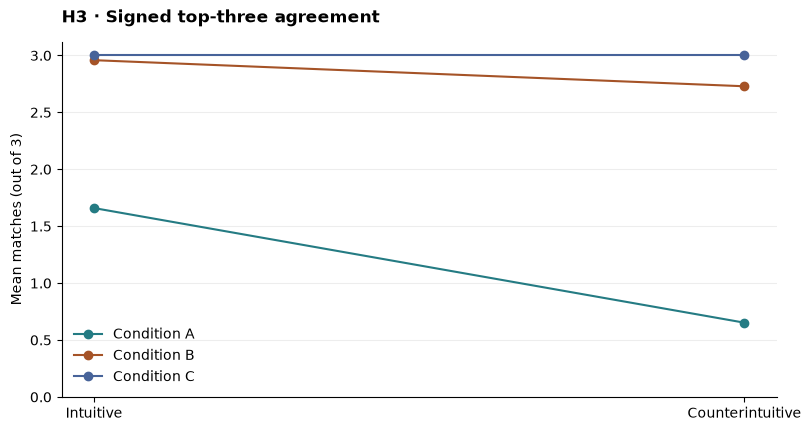

In [5]:
if results:
    display(Markdown("**Table 2. Faithfulness by model behavior and condition**"))
    display(pd.DataFrame(results["faithfulness"]).round(3))
    display(figures["01_h3_interaction"])

## Clinical-expectation substitution and model switching

Substitution requires an explicit direction that matches the prespecified intuitive expectation and contradicts the reversed SHAP direction. Conflicting structured and prose directions count as other incorrect when both are explicit. Omissions join abstentions, with explicit global abstention recorded separately. Failed outputs and ambiguous feature claims are unverifiable. This rubric describes the response and makes no inference about internal reasoning.

A correct switch requires agreement on both sides of a validated local sign flip for the same profile. Retaining the intuitive direction requires initial agreement followed by the same direction under reversal. Top-three-only summaries measure responsiveness when the target is among the requested drivers.

The structured-only summaries score the JSON drivers independently of prose ambiguity. The combined summaries require a direction that can be read consistently across both channels.

,condition,variant,top_three_only,outcome,count,denominator,rate
0,A,intuitive,False,model_faithful,11,96,0.115
1,A,intuitive,False,clinical_expectation_substitution,0,96,0.000
2,A,intuitive,False,other_incorrect,0,96,0.000
3,A,intuitive,False,abstention,13,96,0.135
4,A,intuitive,False,unverifiable,72,96,0.750
5,A,intuitive,True,model_faithful,2,57,0.035
6,A,intuitive,True,clinical_expectation_substitution,0,57,0.000
7,A,intuitive,True,other_incorrect,0,57,0.000
8,A,intuitive,True,abstention,6,57,0.105
9,A,intuitive,True,unverifiable,49,57,0.860


,condition,top_three_in_both_only,outcome,count,denominator,rate
0,A,False,correct_switch,0,96,0.000
1,A,False,retained_intuitive_direction,10,96,0.104
2,A,False,other_incorrect,0,96,0.000
3,A,False,abstention,14,96,0.146
4,A,False,unverifiable,72,96,0.750
5,A,True,correct_switch,0,57,0.000
6,A,True,retained_intuitive_direction,2,57,0.035
7,A,True,other_incorrect,0,57,0.000
8,A,True,abstention,6,57,0.105
9,A,True,unverifiable,49,57,0.860


**Structured JSON drivers only**

,condition,variant,top_three_only,outcome,count,denominator,rate
0,A,intuitive,False,model_faithful,70,96,0.729
1,A,intuitive,False,clinical_expectation_substitution,0,96,0.000
2,A,intuitive,False,other_incorrect,4,96,0.042
3,A,intuitive,False,abstention,14,96,0.146
4,A,intuitive,False,unverifiable,8,96,0.083
5,A,intuitive,True,model_faithful,45,57,0.789
6,A,intuitive,True,clinical_expectation_substitution,0,57,0.000
7,A,intuitive,True,other_incorrect,0,57,0.000
8,A,intuitive,True,abstention,7,57,0.123
9,A,intuitive,True,unverifiable,5,57,0.088


,condition,top_three_in_both_only,outcome,count,denominator,rate
0,A,False,correct_switch,0,96,0.000
1,A,False,retained_intuitive_direction,69,96,0.719
2,A,False,other_incorrect,4,96,0.042
3,A,False,abstention,15,96,0.156
4,A,False,unverifiable,8,96,0.083
5,A,True,correct_switch,0,57,0.000
6,A,True,retained_intuitive_direction,45,57,0.789
7,A,True,other_incorrect,0,57,0.000
8,A,True,abstention,7,57,0.123
9,A,True,unverifiable,5,57,0.088


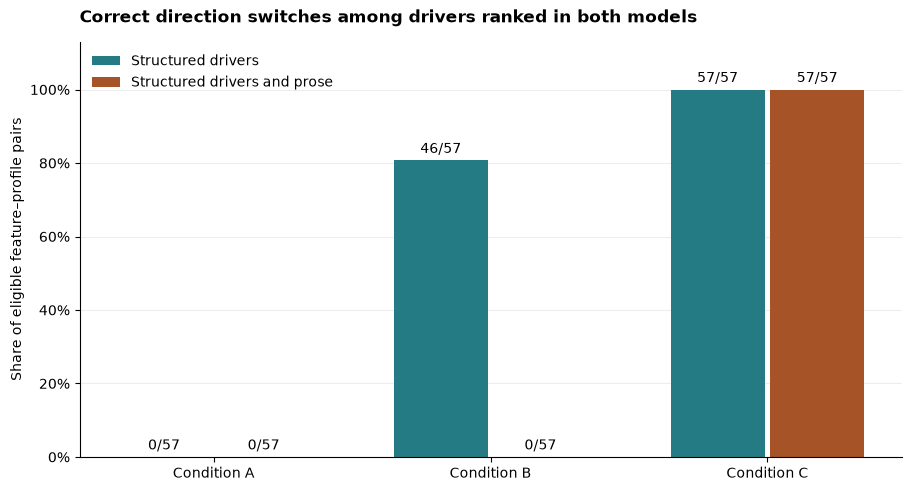

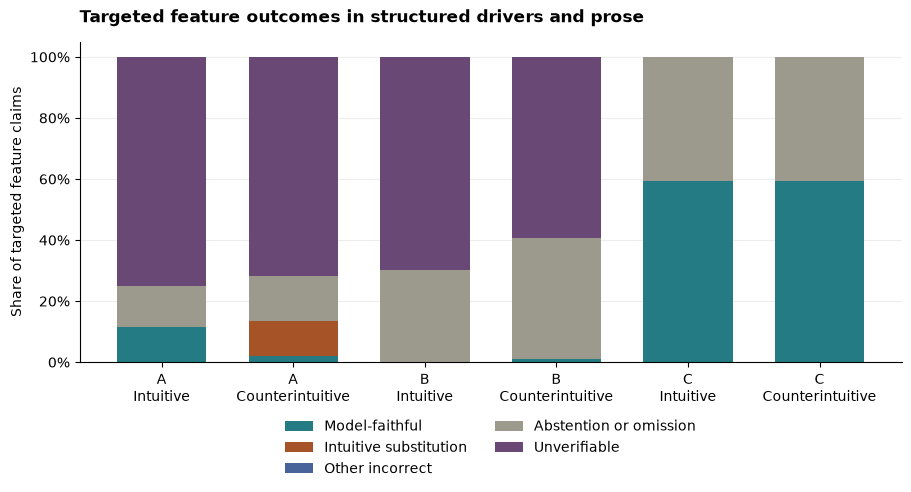

In [6]:
if results:
    display(pd.DataFrame(results["claim_rates"]).round(3))
    display(pd.DataFrame(results["switch_rates"]).round(3))
    display(Markdown("**Structured JSON drivers only**"))
    display(pd.DataFrame(results["structured_claim_rates"]).round(3))
    display(pd.DataFrame(results["structured_switch_rates"]).round(3))
    display(figures["02_model_switch"], figures["03_clinical_substitution"])

## Verification effectiveness

Intervention rates distinguish draft acceptance, Qwen3 revision and fallback. Detected error classes can overlap. Hand-labeled fictional probes cover wrong directions, compound and relative clauses, rank errors and causal wording. Detection requires an explicit contradiction or structured issue. Ambiguity can prevent release and is tracked separately. Scripted corrections in probes measure verifier handling under known inputs.

,variant,completed,interventions,draft_accepted,revision_requested,revision_accepted,revision_rejected,fallback_used,verified_complete
0,intuitive,48,48,0,48,4,44,44,48
1,counterintuitive,48,48,0,48,3,45,45,48


,variant,detected_code,detected,accepted_revision_rate,fallback_rate,verified_complete_rate
0,intuitive,ranking,9,0,1,1
1,intuitive,top_three,2,0,1,1
2,counterintuitive,direction,6,0,1,1


,probe,expected_error,detected,missed,ambiguous,draft_accepted,corrected_with_scripted_revision,corrected_with_fallback,explanation
0,correct control,False,False,False,False,True,False,False,The model estimates a 43.33% readmission proba...
1,wrong direction in prose,True,True,False,False,False,True,True,The model estimates a 43.33% readmission proba...
2,wrong structured direction,True,True,False,False,False,True,True,The model estimates a 43.33% readmission proba...
3,outside top three called strongest,True,True,False,False,False,True,True,hemoglobin is the strongest model driver.
4,compound contradiction,True,True,False,False,False,True,True,prior_admissions increases the model's predict...
5,relative clause contradiction,True,False,False,True,False,True,True,"prior_admissions, which decreases the model's ..."
6,unsupported causation,True,True,False,False,False,True,True,prior_admissions causes readmission.
7,missing directions,False,False,False,False,False,True,True,The model contributions are unknown.


detected                            0.833
missed                              0.000
ambiguous                           0.167
corrected_with_scripted_revision    1.000
corrected_with_fallback             1.000
dtype: float64

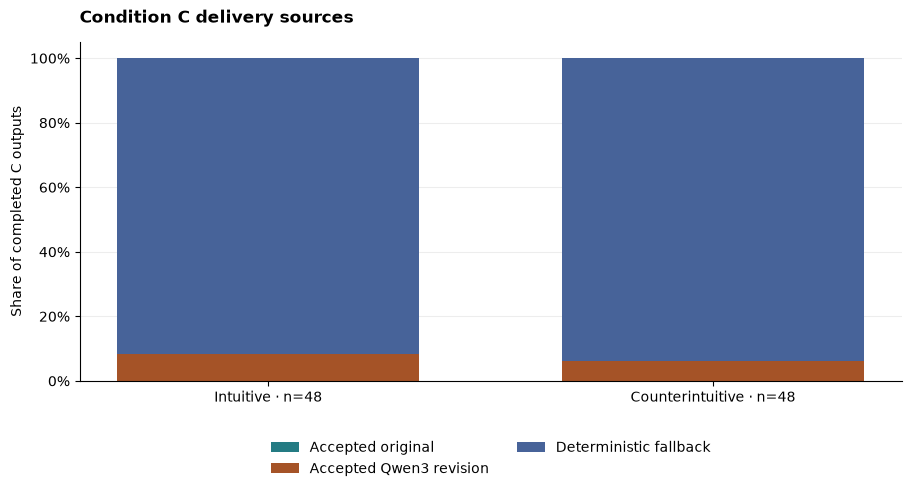

In [7]:
if results:
    display(pd.DataFrame(results["interventions"]))
    display(pd.DataFrame(results["verifier_error_classes"]).round(3))
    probes = pd.DataFrame(results["fictional_verifier_probes"])
    display(probes)
    display(probes[probes.expected_error][
        ["detected", "missed", "ambiguous", "corrected_with_scripted_revision", "corrected_with_fallback"]
    ].mean().round(3))
    display(figures["04_verification_outcomes"])

## Paired H3 contrasts

Differences are counterintuitive minus intuitive. Percentile 95% confidence intervals use 10,000 resamples of whole synthetic profiles with seed 380. Each draw preserves the variants and conditions. The main analysis uses valid pairs. The sensitivity analysis assigns terminal failures zero on bounded agreement and ranking metrics. Family and challenge-attribute contrasts are descriptive. Attribute strata flag whether either member has the property, preserving the match.

intuitive_probability                \
                                   mean    min    max   
family                                                  
age-physiology                    0.345  0.070  0.799   
renal-utilization                 0.378  0.084  0.777   

                  counterintuitive_probability                \
                                          mean    min    max   
family                                                         
age-physiology                           0.163  0.028  0.529   
renal-utilization                        0.120  0.028  0.319   

                  probability_change                
                                mean    min    max  
family                                              
age-physiology                -0.182 -0.484 -0.039  
renal-utilization             -0.258 -0.714 -0.051

,stratum,condition,metric,policy,pairs,selected_pairs,mean_difference,ci95_low,ci95_high
0,all,A,signed_top_three_agreement,valid_pairs,44,48,-1.000,-1.227,-0.762
1,all,A,signed_top_three_agreement,failed_outputs_zero,48,48,-0.896,-1.125,-0.667
7,all,B,signed_top_three_agreement,valid_pairs,48,48,-0.229,-0.479,-0.021
8,all,B,signed_top_three_agreement,failed_outputs_zero,48,48,-0.229,-0.479,-0.021
14,all,C,signed_top_three_agreement,valid_pairs,48,48,0.000,0.000,0.000
15,all,C,signed_top_three_agreement,failed_outputs_zero,48,48,0.000,0.000,0.000
23,renal-utilization,A,signed_top_three_agreement,valid_pairs,22,24,-1.455,-1.696,-1.200
24,renal-utilization,A,signed_top_three_agreement,failed_outputs_zero,24,24,-1.333,-1.583,-1.042
30,renal-utilization,B,signed_top_three_agreement,valid_pairs,24,24,-0.167,-0.417,0.042
31,renal-utilization,B,signed_top_three_agreement,failed_outputs_zero,24,24,-0.167,-0.417,0.042


,stratum,condition,metric,policy,pairs,selected_pairs,mean_difference,ci95_low,ci95_high
2,all,A,exact_top_three_ordering,valid_pairs,44,48,0.000,0.000,0.000
3,all,A,exact_top_three_ordering,failed_outputs_zero,48,48,0.000,0.000,0.000
4,all,A,unsupported_model_claims,valid_pairs,44,48,0.045,0.000,0.116
5,all,A,narrative_contradictions,valid_pairs,44,48,0.045,0.000,0.116
6,all,A,substitution_rate,valid_pairs,44,48,0.125,0.054,0.209
9,all,B,exact_top_three_ordering,valid_pairs,48,48,0.229,0.125,0.354
10,all,B,exact_top_three_ordering,failed_outputs_zero,48,48,0.229,0.125,0.354
11,all,B,unsupported_model_claims,valid_pairs,48,48,0.000,0.000,0.000
12,all,B,narrative_contradictions,valid_pairs,48,48,0.000,0.000,0.000
13,all,B,substitution_rate,valid_pairs,48,48,0.000,0.000,0.000


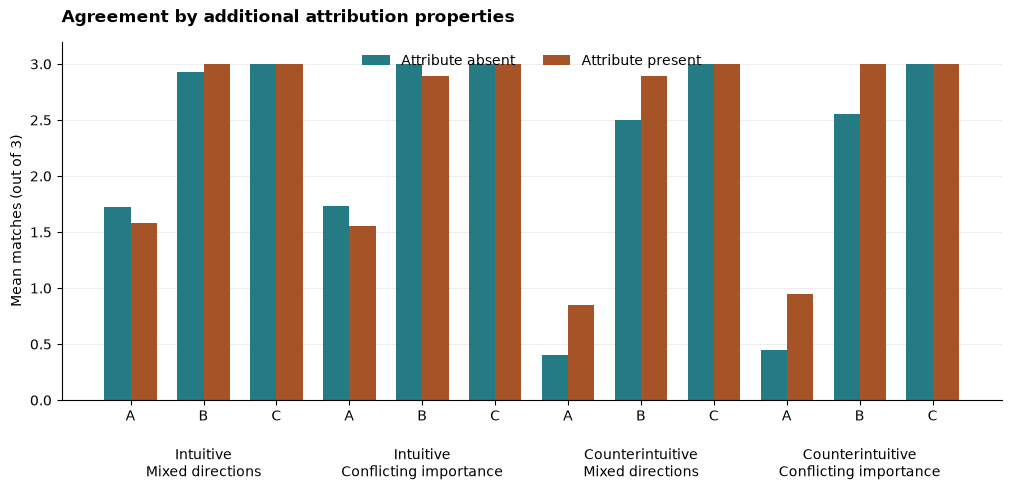

In [8]:
if results:
    shifts = pd.DataFrame(results["prediction_changes"])
    if not shifts.empty:
        display(shifts.groupby("family")[["intuitive_probability", "counterintuitive_probability",
                                          "probability_change"]].agg(["mean", "min", "max"]).round(3))
    paired = pd.DataFrame(results["paired"])
    display(paired.query("metric == 'signed_top_three_agreement'").round(3))
    display(paired.query("stratum == 'all' and metric != 'signed_top_three_agreement'").round(3))
    display(figures["05_attribution_properties"])

## Optional observational MIMIC-IV extension

The aggregate screen reads the saved 72-case XGBoost reference. Prespecified operational cutoffs are 70 years, 2 prior admissions, and 1.5 mg/dL creatinine. The screen assumes a familiar positive local direction at or above each cutoff, and applies the same mixed-direction and importance thresholds as the synthetic analysis. These are screening assumptions. A local sign depends on the feature value, reference and model interactions. Observational counts stay outside the primary H3 estimate.

In [10]:
if SCREEN_PINNED_MIMIC:
    try:
        display(screen_saved_cases())
    except (FileNotFoundError, PermissionError) as error:
        display(Markdown(f"Saved private attributions are unavailable ({type(error).__name__})."))
else:
    display(Markdown("Optional MIMIC-IV screen disabled."))

Optional MIMIC-IV screen disabled.

## Representative fictional examples

Up to two paired profiles illustrate substitution, verifier intervention, or a matched comparison. The feature values, model-specific predictions, signed references and excerpts are synthetic.

In [9]:
if results:
    for example in results["examples"]:
        display(Markdown(f"**{example['profile_id']} · {example['reason']}**"))
        display(pd.DataFrame(example["variants"][0]["features"]))
        for variant in example["variants"]:
            display(Markdown(f"**{variant['variant'].title()} model** · probability {variant['predicted_risk']:.2%}"))
            display(pd.DataFrame(variant["shap"]["contributions"]).sort_values("rank").round(3))
            for condition, answer in variant["explanations"].items():
                print(f"{condition} — {answer['explanation'][:450] if answer else 'No valid output'}")
    if run["execution_mode"] == "real":
        reviewed_draft = (
            "The model predicts an 8.2% risk of readmission. Prior admissions and creatinine "
            "most strongly influence the prediction, increasing risk, while sodium decreases it."
        )
        if any(r.get("parse", {}).get("answer", {}).get("explanation") == reviewed_draft
               for r in run["state"]["records"].values() if r.get("parse", {}).get("answer")):
            display(Markdown(
                "**Independent reading of one live B draft, synthetic-00533.** The structured drivers "
                "correctly gave negative directions for prior admissions and creatinine and a positive "
                "direction for sodium. The prose asserted the opposite directions in a compound sentence. "
                "The verifier flagged the clauses as ambiguous, and C used the deterministic fallback. "
                "This example remains unverifiable under the primary automated prose rubric."
            ))

**synthetic-00533 · Grounded draft verification intervention**

,name,label,unit,value
0,age,Age,years,54.00
1,prior_admissions,Prior hospital admissions,admissions,3.00
2,creatinine,Creatinine,mg/dL,1.53
3,hemoglobin,Hemoglobin,g/dL,12.20
4,sodium,Sodium,mmol/L,135.80
5,heart_rate,Heart rate,bpm,87.00


**Intuitive model** · probability 43.33%

,feature,label,shap,rank,direction
1,prior_admissions,Prior hospital admissions,0.742,1,positive
2,creatinine,Creatinine,0.329,2,positive
4,sodium,Sodium,0.074,3,positive
3,hemoglobin,Hemoglobin,0.065,4,positive
0,age,Age,-0.033,5,negative
5,heart_rate,Heart rate,0.005,6,positive


A — The model's predicted readmission risk is 43.33%. The strongest drivers are prior hospital admissions and creatinine levels, which increase risk, while hemoglobin and sodium levels decrease it.
B — The model predicts a 43.33% risk of readmission. Prior admissions and creatinine levels most strongly increase predicted risk, while sodium levels also contribute positively.
C — The model estimates a 43.33% readmission probability. prior_admissions increases the model's predicted risk relative to the model reference, while creatinine increases the model's predicted risk relative to the model reference, while sodium increases the model's predicted risk relative to the model reference.


**Counterintuitive model** · probability 8.23%

,feature,label,shap,rank,direction
1,prior_admissions,Prior hospital admissions,-0.742,1,negative
2,creatinine,Creatinine,-0.329,2,negative
4,sodium,Sodium,0.074,3,positive
3,hemoglobin,Hemoglobin,0.065,4,positive
0,age,Age,-0.033,5,negative
5,heart_rate,Heart rate,0.005,6,positive


A — The model's predicted readmission risk is 8.23%. The strongest drivers are prior hospital admissions and creatinine levels, which increase risk, while hemoglobin and sodium levels decrease it.
B — The model predicts an 8.2% risk of readmission. Prior admissions and creatinine most strongly influence the prediction, increasing risk, while sodium decreases it.
C — The model estimates a 8.23% readmission probability. prior_admissions decreases the model's predicted risk relative to the model reference, while creatinine decreases the model's predicted risk relative to the model reference, while sodium increases the model's predicted risk relative to the model reference.


**Independent reading of one live B draft, synthetic-00533.** The structured drivers correctly gave negative directions for prior admissions and creatinine and a positive direction for sodium. The prose asserted the opposite directions in a compound sentence. The verifier flagged the clauses as ambiguous, and C used the deterministic fallback. This example remains unverifiable under the primary automated prose rubric.

## Discussion and Experiment 4 handoff

Interpret H3 by condition. The chosen reversals, above-reference profiles, enriched strata and probability differences define the stress test. The frequencies describe this synthetic benchmark. Rule-based coverage depends on wording and feature aliases. The independent probes provide examples for Experiment 4, including relative clauses, mixed-direction statements, contradictory prose and unsupported clinical interpretation.

In [11]:
if results and run["execution_mode"] == "real" and run["state"]["pause_reason"] is None:
    primary = paired.query("stratum == 'all' and metric == 'signed_top_three_agreement' and policy == 'valid_pairs'")
    for row in primary.itertuples():
        if pd.isna(row.ci95_high):
            interpretation = "Insufficient valid pairs to estimate the contrast."
        elif row.ci95_high < 0:
            interpretation = "The interval supports lower agreement under reversal in this condition."
        elif row.ci95_low > 0:
            interpretation = "The interval favors higher agreement under reversal in this condition."
        elif row.ci95_low == row.ci95_high == 0:
            interpretation = "Observed paired differences were zero."
        else:
            interpretation = "The interval includes zero, leaving the directional contrast inconclusive."
        display(Markdown(f"**Condition {row.condition}.** {interpretation}"))

**Condition A.** The interval supports lower agreement under reversal in this condition.

**Condition B.** The interval supports lower agreement under reversal in this condition.

**Condition C.** Observed paired differences were zero.